# Data-Free Metrics Don't Work: MNIST Example

This notebook goes through training the MNIST model used in paper, evaluating it with weightwatcher, randomising the layers and observing the new performance and metrics.

**If you are using Google Colab please run the pip command as all other packages are already in the environment.**

In [ ]:
! pip install weightwatcher

## 1.Training MNIST Model
This section outlines training an MNIST model.

### 1.1 Importing Required Packages

In [ ]:
import os

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import torchvision
import weightwatcher as ww
from torch import nn, optim
from torchvision import transforms
from tqdm import tqdm

### 1.2 Dynamically Set the Device

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### 1.3 Get the Training and Testing Dataset

In [ ]:
transform = transforms.Compose(
    [transforms.ToTensor()])

batch_size = 128

trainset = torchvision.datasets.MNIST(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.MNIST(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

### 1.4 Create the Training and Testing Functions

In [ ]:
def train(dataloader, epochs, net):
    for epoch in tqdm(range(epochs)):  # loop over the dataset multiple times
        for data in dataloader:
            # Get the inputs; data is a list of [inputs, labels]
            inputs, labels = data[0].to(device), data[1].to(device)

            # Zero the parameter gradients
            optimizer.zero_grad()

            # Forward + backward + optimize
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()


def evaluate(test_data, model):
    running_loss = 0
    total = 0
    correct = 0
    model.eval()
    with torch.no_grad():
        for iters, data in enumerate(test_data):
            images, labels = data[0].to(device), data[1].to(device)
            # Calculate outputs by running images through the network
            outputs = model(images)
            loss = torch.nn.CrossEntropyLoss()(outputs, labels)
            running_loss += loss.item()
            # The class with the highest energy is what we choose as prediction
            predicted = torch.argmax(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return (
        100 * correct / total,
        running_loss / (iters + 1),
    )

### 1.5 Creating Model

In [ ]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 512)
        self.fc2 = nn.Linear(512, 512)
        self.fc3 = nn.Linear(512, 512)
        self.fc4 = nn.Linear(512, 512)
        self.fc5 = nn.Linear(512, 512)
        self.fc6 = nn.Linear(512, 10)

    def forward(self, x):
        x = x.reshape(-1, 784)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = F.relu(self.fc4(x))
        x = F.relu(self.fc5(x))
        x = self.fc6(x)
        return x


### 1.6 Initialise and Train the Model

In [ ]:
model = MLP()
torch.save( model.state_dict(), "model_init.pth")
model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
train(trainloader, 25, model)

  0%|          | 0/25 [00:07<?, ?it/s]


KeyboardInterrupt: 

### 1.7 Evaluate the Model

In [ ]:
acc, loss = evaluate(testloader,model)
print(f"Accuracy: {acc}, Loss: {loss}")

### 1.8 Observe Data-Free Metrics

In [ ]:
watcher = ww.WeightWatcher(model=model)
details = watcher.analyze(mp_fit=True)
details

SMALL N PL FIT


,layer_id,name,D,M,N,Q,W_scale,alpha,alpha_weighted,bulk_max,...,sigma_mp,spectral_norm,stable_rank,status,sv_max,sv_min,warning,weak_rank_loss,xmax,xmin
0,1,fc1,0.053935,512,784,1.53125,1.666007,4.871302,2.193436,1.208342,...,1.012847,2.820182,65.409223,success,1.679340,0.113830,,0,2.820182,0.763427
1,2,fc2,0.091844,512,512,1.00000,1.671590,3.902080,2.539965,1.440770,...,1.003222,4.476369,40.934016,success,2.115743,0.000902,,1,4.476369,0.692721
2,3,fc3,0.090529,512,512,1.00000,1.667383,3.989435,2.606834,1.447695,...,1.003099,4.502301,40.903884,success,2.121863,0.000341,,1,4.502301,0.709224
3,4,fc4,0.094860,512,512,1.00000,1.665693,3.820468,2.537385,1.450886,...,1.003186,4.614826,39.987547,success,2.148215,0.000077,,1,4.614826,0.682851
4,5,fc5,0.096158,512,512,1.00000,1.666311,3.832535,2.605744,1.449505,...,1.003081,4.785207,38.535171,success,2.187512,0.001054,,0,4.785207,0.688601
5,6,fc6,0.191473,10,512,51.20000,0.748223,1.647065,1.108535,0.943059,...,0.637513,4.710172,3.792290,success,2.170293,0.559477,over-trained,0,4.710172,0.313014


$2\leq\alpha\leq6$ is considered a good layer and or model.

In [ ]:
details["alpha"], details["alpha"].mean()

(0    4.871302
 1    3.902080
 2    3.989435
 3    3.820468
 4    3.832535
 5    1.647065
 Name: alpha, dtype: float64,
 np.float64(3.6771476568337067))

### 1.9 Save the Model

In [ ]:
torch.save(model.state_dict(), "model_trained.pth")

## 2.Re-initialising and Re-randomising the Layers
This section demonstrates how re-initialising and re-randomising the layers affects the performance of the model and the corresponding data-free metrics

### 2.1 Get Model Initialisation

In [ ]:
init_model = MLP()
init_state_dict = torch.load("model_init.pth")
init_model.load_state_dict(init_state_dict)

### 2.2 Get a Random Model

In [ ]:
random_model = MLP()
if os.path.exists("model_random.pth"):
    random_state_dict = torch.load("model_random.pth")
    random_model.load_state_dict(random_state_dict)
else:
    torch.save(random_model.state_dict(), "model_random.pth")

### 2.3 Get the Trained Model

In [ ]:
def get_trained_model():
    trained_model = MLP()
    trained_state_dict = torch.load("model_trained.pth")
    trained_model.load_state_dict(trained_state_dict)
    return trained_model
trained_model = get_trained_model()

### 2.4 Evalulate Layers

In [ ]:
performance = {"init": {}, "random": {}}
layers = ["fc1", "fc2", "fc3", "fc4", "fc5", "fc6"]
for layer_name in layers:
    for idx, change_model in enumerate([init_model, random_model]):
      trained_model = get_trained_model()
      trained_model.to(device)
      trained_model.eval()
      trained_model.set_submodule(layer_name, change_model.get_submodule(layer_name))
      acc, loss = evaluate(testloader,trained_model)
      if idx == 0:
          performance["init"][layer_name] = {"acc": acc, "loss": loss}
      else:
          performance["random"][layer_name] = {"acc": acc, "loss": loss}

In [ ]:
performance

{'init': {'fc1': {'acc': 62.19, 'loss': 1.0992963238607478},
  'fc2': {'acc': 84.31, 'loss': 0.5790858989274954},
  'fc3': {'acc': 94.34, 'loss': 0.5390248721158957},
  'fc4': {'acc': 95.21, 'loss': 0.5882686293577846},
  'fc5': {'acc': 94.12, 'loss': 0.6512654793413379},
  'fc6': {'acc': 87.79, 'loss': 0.7857641630534884}},
 'random': {'fc1': {'acc': 6.22, 'loss': 3.598645315894598},
  'fc2': {'acc': 12.8, 'loss': 2.52283988723272},
  'fc3': {'acc': 15.21, 'loss': 2.733858748327328},
  'fc4': {'acc': 9.89, 'loss': 2.4471407268620746},
  'fc5': {'acc': 10.28, 'loss': 2.5489496732059913},
  'fc6': {'acc': 12.9, 'loss': 2.229549341563937}}}

**Notice the performance difference between the init and the random. Re-initialisation maintains performance. Re-randomisation reduces the performance to near random accuracy. This is as observed in the paper.**

### 2.5 Initialisation Model: Data-Free Metrics

In [ ]:
watcher = ww.WeightWatcher(model=init_model)
init_details = watcher.analyze(mp_fit=True)
init_details

SMALL N PL FIT


,layer_id,name,D,M,N,Q,W_scale,alpha,alpha_weighted,bulk_max,...,sigma_mp,spectral_norm,stable_rank,status,sv_max,sv_min,warning,weak_rank_loss,xmax,xmin
0,1,fc1,0.114743,512,784,1.53125,1.733899,10.034970,0.320974,1.092202,...,1.002184,1.076429,158.211006,success,1.037511,0.108946,under-trained,0,1.076429,0.821847
1,2,fc2,0.132361,512,512,1.00000,1.736488,6.503418,0.730813,1.345010,...,1.006942,1.295310,131.084944,success,1.138117,0.001130,under-trained,0,1.295310,0.856754
2,3,fc3,0.137404,512,512,1.00000,1.731394,13.708195,1.532549,1.352962,...,1.006952,1.293594,132.032233,success,1.137363,0.000791,under-trained,1,1.293594,1.083047
3,4,fc4,0.134180,512,512,1.00000,1.730328,10.991530,1.246221,1.354727,...,1.006988,1.298315,131.714365,success,1.139436,0.000955,under-trained,1,1.298315,1.026476
4,5,fc5,0.132761,512,512,1.00000,1.732947,5.588774,0.613375,1.351327,...,1.007246,1.287512,132.418341,success,1.134686,0.001182,,0,1.287512,0.786990
5,6,fc6,0.168150,10,512,51.20000,1.739351,8.438794,-3.320924,0.432971,...,1.004166,0.404082,8.180055,success,0.635674,0.527932,under-trained,0,0.404082,0.303537


In [ ]:
init_details["alpha"], init_details["alpha"].mean()

(0    10.034970
 1     6.503418
 2    13.708195
 3    10.991530
 4     5.588774
 5     8.438794
 Name: alpha, dtype: float64,
 np.float64(9.210947006500922))

### 2.6 Random Model: Data-Free Metrics

In [ ]:
watcher = ww.WeightWatcher(model=random_model)
random_details = watcher.analyze(mp_fit=True)
random_details

SMALL N PL FIT


,layer_id,name,D,M,N,Q,W_scale,alpha,alpha_weighted,bulk_max,...,sigma_mp,spectral_norm,stable_rank,status,sv_max,sv_min,warning,weak_rank_loss,xmax,xmin
0,1,fc1,0.125325,512,784,1.53125,1.732269,9.870561,0.263673,1.081077,...,0.996129,1.063440,160.445068,success,1.031232,0.110654,under-trained,0,1.063440,0.814712
1,2,fc2,0.133629,512,512,1.00000,1.729391,8.573556,1.028224,1.355852,...,1.006860,1.318043,129.883528,success,1.148061,0.000851,under-trained,1,1.318043,0.967644
2,3,fc3,0.139117,512,512,1.00000,1.732509,9.154743,0.997258,1.351396,...,1.007017,1.285090,132.734974,success,1.133618,0.000125,under-trained,1,1.285090,0.981436
3,4,fc4,0.137880,512,512,1.00000,1.731928,4.623852,0.561704,1.353827,...,1.007584,1.322756,129.041891,success,1.150111,0.000348,,1,1.322756,0.699579
4,5,fc5,0.135256,512,512,1.00000,1.731993,8.404785,0.980559,1.352270,...,1.007042,1.308178,130.470142,success,1.143756,0.001270,under-trained,0,1.308178,0.949412
5,6,fc6,0.188142,10,512,51.20000,1.745379,5.399303,-2.191721,0.424738,...,0.998020,0.392711,8.358860,success,0.626667,0.515237,,0,0.392711,0.265470


In [ ]:
random_details["alpha"], random_details["alpha"].mean()

(0    9.870561
 1    8.573556
 2    9.154743
 3    4.623852
 4    8.404785
 5    5.399303
 Name: alpha, dtype: float64,
 np.float64(7.67113331184265))

### 2.7 Plotting the Relationship: Data-Free Metric Vs Test Accuracy

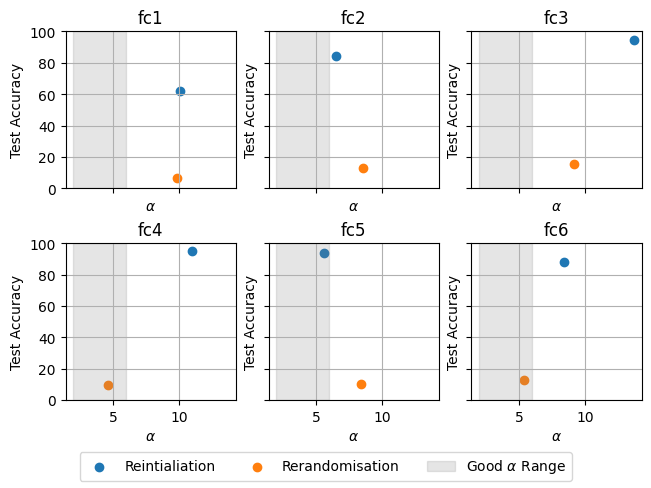

In [ ]:
fig,axs = plt.subplots(2,3, constrained_layout=True, sharex=True, sharey=True)
axs = axs.flatten()
for idx, ax in enumerate(axs):
  inits = ax.scatter(init_details["alpha"][idx], performance["init"][layers[idx]]["acc"], color="tab:blue")
  randoms = ax.scatter(random_details["alpha"][idx], performance["random"][layers[idx]]["acc"], color="tab:orange")
  ax.grid()
  ax.set_title(layers[idx])
  ax.set_ylim(0,100)
  alpha_range = ax.axvspan(2,6, color="grey", alpha=0.2)
  ax.set_xlabel(r"$\alpha$")
  ax.set_ylabel(r"Test Accuracy")
fig.legend([inits, randoms, alpha_range], ["Reintialiation", "Rerandomisation", r"Good $\alpha$ Range"], loc='outside lower center', ncol=3)
plt.show()

## 3.Empirical Distribution of $\alpha$ Values.

This section plots the emperical distrubtion of $\alpha$ for random layers.

### 3.1 784x512 Linear Layer

In [ ]:
metrics = []
for i in tqdm(range(100)):
  layer = torch.nn.Linear(784,512)
  watcher = ww.WeightWatcher(model=layer)
  details = watcher.analyze(mp_fit=True)
  metrics.append(details.to_numpy()[0])

metrics = np.array(metrics)
key_to_index = {}
for idx, key in enumerate(details.keys()):
  key_to_index[key] = idx


100%|██████████| 100/100 [04:15<00:00,  2.55s/it]


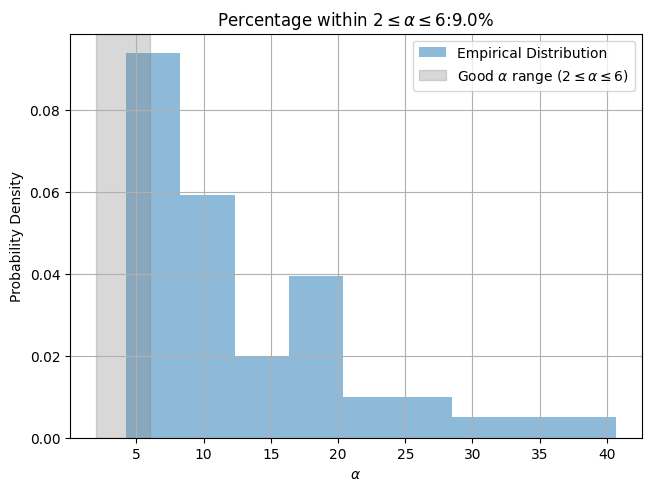

In [ ]:
fig, ax = plt.subplots(constrained_layout=True)
alphas = metrics[:,key_to_index["alpha"]]
ax.hist(alphas,bins="fd", density=True, alpha=0.5, label="Empirical Distribution")
alpha_range = ax.axvspan(2,6, color="grey", alpha=0.3, label=r"Good $\alpha$ range ($2\leq\alpha\leq6$)")
good_layers = alphas[(alphas >= 2) & (alphas <= 6)]

ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(r"Probability Density")
ax.set_title(r"Percentage $2\leq\alpha\leq6$:" + f"{(len(good_layers)/len(alphas))*100}%")
ax.legend()
ax.grid()
plt.show()

### 3.2 512x512 Linear Layer

In [ ]:
metrics = []
for i in tqdm(range(100)):
  layer = torch.nn.Linear(512,512)
  watcher = ww.WeightWatcher(model=layer)
  details = watcher.analyze(mp_fit=True)
  metrics.append(details.to_numpy()[0])

metrics = np.array(metrics)
key_to_index = {}
for idx, key in enumerate(details.keys()):
  key_to_index[key] = idx


100%|██████████| 100/100 [03:46<00:00,  2.26s/it]


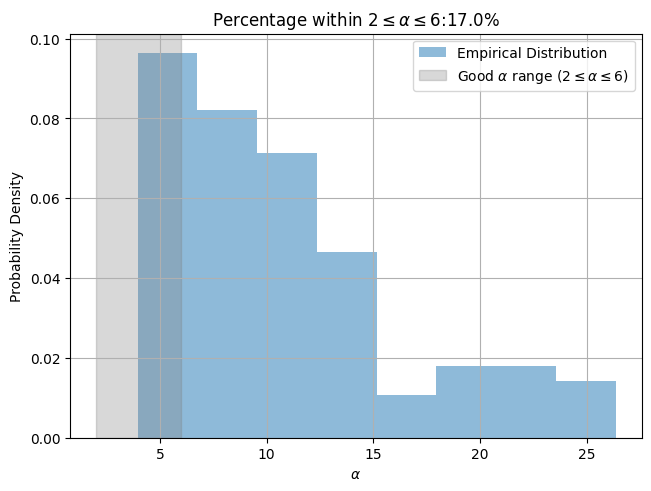

In [ ]:
fig, ax = plt.subplots(constrained_layout=True)
alphas = metrics[:,key_to_index["alpha"]]
ax.hist(alphas,bins="fd", density=True, alpha=0.5, label="Empirical Distribution")
alpha_range = ax.axvspan(2,6, color="grey", alpha=0.3, label=r"Good $\alpha$ range ($2\leq\alpha\leq6$)")
good_layers = alphas[(alphas >= 2) & (alphas <= 6)]

ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(r"Probability Density")
ax.set_title(r"Percentage $2\leq\alpha\leq6$:" + f"{(len(good_layers)/len(alphas))*100}%")
ax.legend()
ax.grid()
plt.show()

### 3.3 512x10 Linear Layer

In [ ]:
metrics = []
for i in tqdm(range(100)):
  layer = torch.nn.Linear(512,10)
  watcher = ww.WeightWatcher(model=layer)
  details = watcher.analyze(mp_fit=True)
  metrics.append(details.to_numpy()[0])

metrics = np.array(metrics)
key_to_index = {}
for idx, key in enumerate(details.keys()):
  key_to_index[key] = idx


  0%|          | 0/100 [00:00<?, ?it/s]

SMALL N PL FIT


  1%|          | 1/100 [00:00<00:57,  1.73it/s]

SMALL N PL FIT


  2%|▏         | 2/100 [00:00<00:43,  2.23it/s]

...

 98%|█████████▊| 98/100 [00:45<00:00,  2.10it/s]

SMALL N PL FIT


 99%|█████████▉| 99/100 [00:46<00:00,  2.29it/s]

SMALL N PL FIT


100%|██████████| 100/100 [00:46<00:00,  2.14it/s]


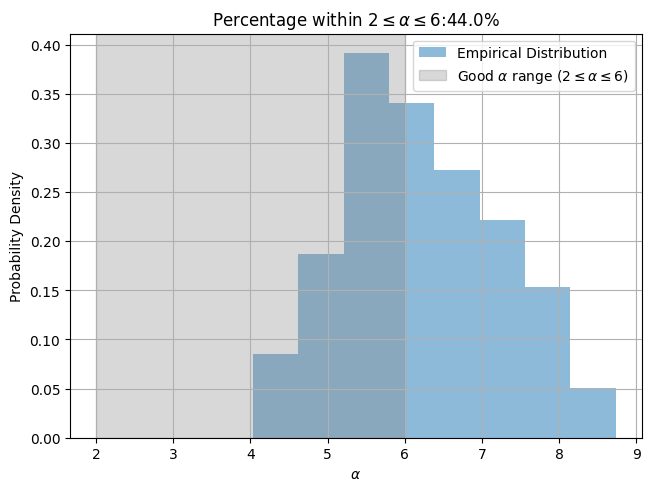

In [ ]:
fig, ax = plt.subplots(constrained_layout=True)
alphas = metrics[:,key_to_index["alpha"]]
ax.hist(alphas,bins="fd", density=True, alpha=0.5, label="Empirical Distribution")
alpha_range = ax.axvspan(2,6, color="grey", alpha=0.3, label=r"Good $\alpha$ range ($2\leq\alpha\leq6$)")
good_layers = alphas[(alphas >= 2) & (alphas <= 6)]

ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(r"Probability Density")
ax.set_title(r"Percentage $2\leq\alpha\leq6$:" + f"{(len(good_layers)/len(alphas))*100}%")
ax.legend()
ax.grid()
plt.show()

## 4.Any $\alpha$ at Initalisation.

This section, shows that a model can be initailsed with any $\alpha$ value prior to training and achieve random accuracy.

In [ ]:
init_model = MLP()
init_state_dict = torch.load("model_init.pth")
init_model.load_state_dict(init_state_dict)

<All keys matched successfully>

Get the interpolation points and colormaps so the plots look nice.

In [ ]:
samples = 21
values_lin = np.linspace(1, 0, samples)
values_log = list(np.geomspace(0.1, 100, samples))
values_log[-1] = 100000
del values_log[0]
points = np.hstack((-values_lin, values_log))
points[20] = 0
points = points+1

samples = 21
R_colors = mpl.colormaps["Reds_r"](np.linspace(0, 1, 21))
R_colors[-1] = [0, 0, 0, 1]
B_colors = mpl.colormaps["Blues"](np.linspace(0, 1, 21))
B_colors[0] = [0, 0, 0, 1]
colors = np.vstack([R_colors, B_colors])
colors = list(colors)
del colors[samples - 1]

In [ ]:
points

array([0.00000000e+00, 5.00000000e-02, 1.00000000e-01, 1.50000000e-01,
       2.00000000e-01, 2.50000000e-01, 3.00000000e-01, 3.50000000e-01,
       4.00000000e-01, 4.50000000e-01, 5.00000000e-01, 5.50000000e-01,
       6.00000000e-01, 6.50000000e-01, 7.00000000e-01, 7.50000000e-01,
       8.00000000e-01, 8.50000000e-01, 9.00000000e-01, 9.50000000e-01,
       1.00000000e+00, 1.14125375e+00, 1.19952623e+00, 1.28183829e+00,
       1.39810717e+00, 1.56234133e+00, 1.79432823e+00, 2.12201845e+00,
       2.58489319e+00, 3.23872114e+00, 4.16227766e+00, 5.46683592e+00,
       7.30957344e+00, 9.91250938e+00, 1.35892541e+01, 1.87827941e+01,
       2.61188643e+01, 3.64813389e+01, 5.11187234e+01, 7.17945784e+01,
       1.00001000e+05])

Get the singular values: $\sigma(t) = \sigma_{\infty}(\frac{\sigma}{\sigma_{\infty}})^t$ where t = `points`

In [ ]:
layer_singular_values = {}
layer_U_and_V = {}
for layer in layers:
  U,S,V = torch.linalg.svd(init_state_dict[f"{layer}.weight"], full_matrices=False)
  layer_U_and_V[layer] = {"U": U, "V":V}
  S = S.numpy()
  S_max = max(S)
  Ss = [S/S_max]*len(points)
  Ss = np.array(Ss)
  for idx in range(len(points)):
    Ss[idx] = (Ss[idx]**points[idx])*S_max
  layer_singular_values[layer] = torch.tensor(Ss)

**Plotting how the interpolation point affects the singular values.**

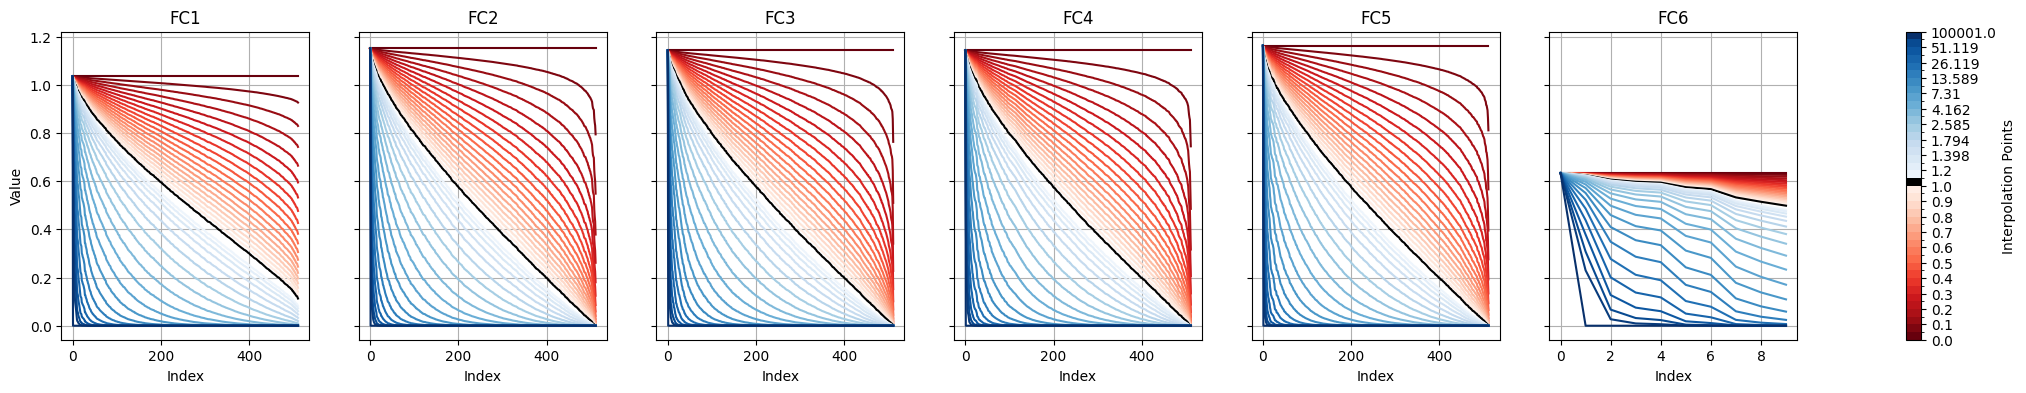

In [ ]:
fig, ax  = plt.subplots(1,6,figsize=(28,4), sharey=True)
for idx, a in enumerate(ax):
    layer = layers[idx]
    for i in range(41):

        a.plot(layer_singular_values[layer][i].numpy(), color=colors[i])
        a.grid()
        a.set_xlabel("Index")
        a.set_title(f"FC{idx+1}")
ax[0].set_ylabel("Value")

cmap = mpl.colors.ListedColormap(colors)
bounds = np.arange(41)

norm = mpl.colors.BoundaryNorm(bounds, 41)

sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)

sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.ax.set_yticks(bounds[::2],np.array(points).round(3)[::2])
cbar.ax.set_ylabel("Interpolation Points")
plt.show()

In [ ]:
accs = []
losses = []
metrics = []
for interpolation in tqdm(range(len(points))):
    for layer in layers:
        U = layer_U_and_V[layer]["U"]
        S = layer_singular_values[layer][interpolation]
        V = layer_U_and_V[layer]["V"]
        init_state_dict[f"{layer}.weight"] = (U*S)@V
    init_model.load_state_dict(init_state_dict)
    init_model.to(device)
    init_model.eval()
    acc, loss = evaluate(testloader,init_model)
    accs.append(acc)
    losses.append(loss)
    watcher = ww.WeightWatcher(model=init_model)
    details = watcher.analyze(mp_fit=True)
    metrics.append(details.to_numpy())


  0%|          | 0/41 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/weightwatcher/weightwatcher.py:4588: RuntimeWarning: overflow encountered in scalar power
  log_alpha_norm = np.log10(np.sum( [ ev**alpha for ev in evals]))
/usr/local/lib/python3.13/dist-packages/weightwatcher/weightwatcher.py:4588: RuntimeWarning: overflow encountered in scalar power
  log_alpha_norm = np.log10(np.sum( [ ev**alpha for ev in evals]))
/usr/local/lib/python3.13/dist-packages/weightwatcher/weightwatcher.py:4588: RuntimeWarning: overflow encountered in scalar power
  log_alpha_norm = np.log10(np.sum( [ ev**alpha for ev in evals]))
/usr/local/lib/python3.13/dist-packages/weightwatcher/weightwatcher.py:4588: RuntimeWarning: overflow encountered in scalar power
  log_alpha_norm = np.log10(np.sum( [ ev**alpha for ev in evals]))
/usr/local/lib/python3.13/dist-packages/weightwatcher/weightwatcher.py:4588: RuntimeWarning: overflow encountered in scalar power
  log_alpha_norm = np.log10(np.sum( [ ev**al

SMALL N PL FIT


/usr/local/lib/python3.13/dist-packages/weightwatcher/weightwatcher.py:4588: RuntimeWarning: divide by zero encountered in log10
  log_alpha_norm = np.log10(np.sum( [ ev**alpha for ev in evals]))
  2%|▏         | 1/41 [00:11<07:49, 11.73s/it]

SMALL N PL FIT


  5%|▍         | 2/41 [00:23<07:47, 12.00s/it]

...

SMALL N PL FIT


SMALL N PL FIT


SMALL N PL FIT


SMALL N PL FIT


100%|██████████| 41/41 [07:43<00:00, 11.31s/it]


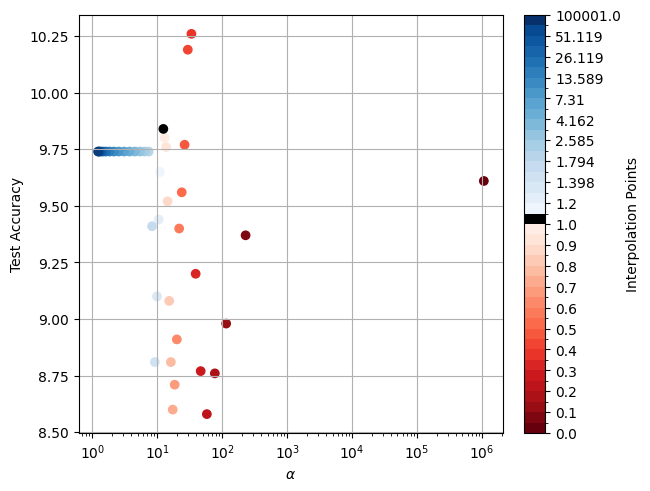

In [ ]:
metrics = np.array(metrics)
key_to_index = {}
for idx, key in enumerate(details.keys()):
  key_to_index[key] = idx
fig, ax = plt.subplots(constrained_layout=True)
ax.scatter(metrics[:,:,key_to_index["alpha"]].mean(axis=1), accs, color=colors)
ax.set_xscale("log")
ax.set_xlabel(r"$\alpha$")
ax.set_ylabel("Test Accuracy")
ax.grid()
cmap = mpl.colors.ListedColormap(colors)
bounds = np.arange(41)

norm = mpl.colors.BoundaryNorm(bounds, 41)

sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)

sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.ax.set_yticks(bounds[::2],np.array(points).round(3)[::2])
cbar.ax.set_ylabel("Interpolation Points")
plt.show()